# Empirical-Bayes Multi-modal Contrastive Analysis (EB-MoCAVI)

Empirical-Bayes Multi-modal Contrastive Analysis (EB-MoCAVI) is a generative model designed to analyze single-cell multi-omics data and for prediction of perturbation effects via an empirical-Bayes framework. In this tutorial, we will demonstrate how to use EB-MoCAVI to predict perturbation effects on gene expression based on optical pooled screening data. We refer to the reader to the original MoCAVI tutorial for details on data preprocessing and model training. Here, we will focus on the empirical-Bayes aspects of EB-MoCAVI.

In [1]:
import numpy as np
import pandas as pd
import scanpy as sc
import scvi
import torch
from tqdm import tqdm

from mocavi import EBMoCAVIModel

# make sure cuda is available
print("CUDA available:", torch.cuda.is_available())

scvi.settings.seed = 0
print("Last run with scvi-tools version:", scvi.__version__)

/home/ubuntu/miniforge3/envs/opensource/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/ubuntu/miniforge3/envs/opensource/lib/python3.10/site-packages/docrep/decorators.py:43: SyntaxWarning: 'param_categorical_covariate_keys' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
/home/ubuntu/miniforge3/envs/opensource/lib/python3.10/site-packages/docrep/decorators.py:43: SyntaxWarning: 'param_continuous_covariate_keys' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
Seed set to 0


CUDA available: True
Last run with scvi-tools version: 1.3.0


To get started, download the data used in the tutorial

```bash
mkdir data && cd data
curl -L -A "Mozilla/5.0" -o main_ops_bulk.h5ad "https://figshare.com/ndownloader/files/59971082?private_link=9670a98d3a8ad87fb802"
curl -L -A "Mozilla/5.0" -o main_pseq_singlecell.h5ad "https://figshare.com/ndownloader/files/59971088?private_link=9670a98d3a8ad87fb802"
cd ..
```

If the curl command does not work, please download the file manually from the link using a web browser.

In [2]:
# let's load the pseq data
adata = sc.read_h5ad("../data/main_pseq_singlecell.h5ad")
adata

AnnData object with n_obs × n_vars = 136906 × 10000
    obs: 'batch', 'Total_UMI', 'MT_UMI', 'Percent_MT_UMI', 'log10_Total_UMI', 'Total_ADT', 'Total_HTO', 'Total_GRNA', 'hto_label', 'grna_label', 'perturb_label', 'Log_Total_UMI', 'Log_Total_ADT', 'score_s', 'score_g2m', 'leiden', 'score_hotspot1', 'score_hotspot2', 'score_hotspot3', 'score_hotspot4', 'score_hotspot5', 'score_hotspot6', 'score_hotspot7', '_scvi_labels', '_scvi_batch', 'perturb_DE', 'perturb_leiden', 'perturb_leiden_mocavi', 'perturb_leiden_salient'
    var: 'n_counts', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches'
    uns: '_scvi_manager_uuid', '_scvi_uuid', 'batch_colors', 'guide_distance', 'hto_label_colors', 'hvg', 'leiden', 'log1p', 'neighbors', 'pca', 'perturb_leiden_colors', 'perturb_leiden_mocavi_colors', 'perturb_leiden_salient_colors', 'protein_names', 'umap'
    obsm: 'X_background_umap', 'X_pca', 'X_salient_umap', 'X_totalVI', 'X_totalVI_umap', 

In [12]:
# for the sake of the tutorial we will reduce the number of genes
# we recommend using more highly variable genes for better results (5,000-10,000)
sc.pp.highly_variable_genes(
    adata,
    n_top_genes=3000,
    subset=True,
    flavor="seurat_v3",
    batch_key="batch",
    layer="counts",
)
adata.layers["counts"] = adata.layers["counts"].todense()

/home/ubuntu/miniforge3/envs/opensource/lib/python3.10/site-packages/anndata/_core/storage.py:39: ImplicitModificationWarning: Layer 'counts' should not be a np.matrix, use np.ndarray instead.
  warnings.warn(msg, ImplicitModificationWarning)


In [13]:
# the obs field "perturb_DE" contains the perturbation information
adata.obs["perturb_DE"].value_counts()

perturb_DE
Control    25952
Cdkn1a      1164
Ikzf1       1022
Med25        826
Mettl14      781
           ...  
Polr2j        52
Orc6          49
Tinf2         48
Lrr1          46
Kif23         44
Name: count, Length: 515, dtype: int64

In [14]:
# let's load the ops bulk data
bulk_ops = sc.read_h5ad("../data/main_ops_bulk.h5ad")
bulk_ops

AnnData object with n_obs × n_vars = 1689 × 70
    obs: 'norms', 'olfr', 'guide_distance', 'nuclei_solidity', 'cell_orientation', 'cell_solidity', 'nuclei_extent', 'nuclei_compactness', 'nuclei_axisminorlength', 'nuclei_areaconvex', 'cell_areaconvex', 'cell_perimeter', 'nuclei_eccentricity', 'nuclei_orientation', 'nuclei_formfactor', 'nuclei_axismajorlength', 'cell_formfactor', 'cell_compactness', 'nuclei_perimeter', 'cell_axisminorlength', 'cell_axismajorlength', 'cell_eccentricity', 'cell_extent', 'nuclei_area', 'cell_area', 'leiden', 'leiden_euclidean'

In [15]:
# check for intersection of perturbation list
pseq_genes = adata.obs["perturb_DE"].unique().tolist()
ops_genes = bulk_ops.obs_names
print("Number of genes in pseq:", len(pseq_genes))
print("Number of genes in ops:", len(ops_genes))
print("Number of genes in common:", len(set(pseq_genes) & set(ops_genes)))
common_genes = list(set(pseq_genes) & set(ops_genes))
# reduce to common genes
adata = adata[adata.obs["perturb_DE"].isin(common_genes + ["Control"]), :].copy()
bulk_ops = bulk_ops[common_genes, :].copy()

Number of genes in pseq: 515
Number of genes in ops: 1689
Number of genes in common: 514


In [16]:
# now we would like to add the OP embedding of each perturbations to the dataframe
n_features = bulk_ops.shape[1]
emb_obsm = pd.DataFrame(np.zeros((adata.shape[0], n_features)), index=adata.obs_names, columns=bulk_ops.var_names)
for cell_id in tqdm(adata.obs_names):
    # get the perturbation of the cell
    perturbation = adata.obs.loc[cell_id, "perturb_DE"]
    # add the embedding to the dataframe
    if perturbation == "Control":
        emb_obsm.loc[cell_id] = np.zeros((1, n_features))
    else:
        emb_obsm.loc[cell_id] = bulk_ops[perturbation].X
# add the embedding to the adata object
adata.obsm["embedding_ops"] = emb_obsm.values

100%|██████████| 135668/135668 [01:01<00:00, 2205.12it/s]


INFO     Using column names from adata.uns['protein_names']                                                        


INFO     Generating sequential column names                                                                        


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
/home/ubuntu/miniforge3/envs/opensource/lib/python3.10/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=63` in the `DataLoader` to improve performance.
/home/ubuntu/miniforge3/envs/opensource/lib/python3.10/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=63` in the `DataLoader` to improve performance.


Epoch 50/50: 100%|██████████| 50/50 [19:16<00:00, 23.06s/it, v_num=1, train_loss_step=1.42e+3, train_loss_epoch=1.44e+3]

`Trainer.fit` stopped: `max_epochs=50` reached.


Epoch 50/50: 100%|██████████| 50/50 [19:16<00:00, 23.13s/it, v_num=1, train_loss_step=1.42e+3, train_loss_epoch=1.44e+3]


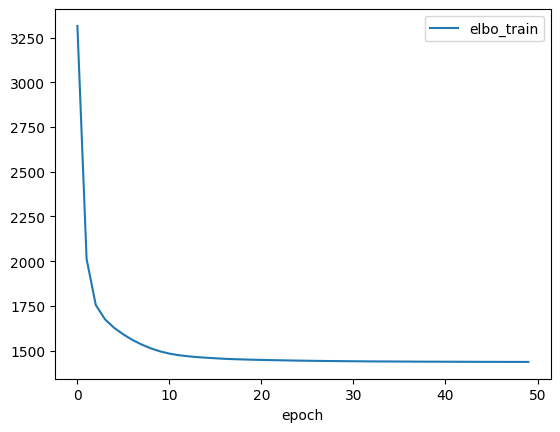

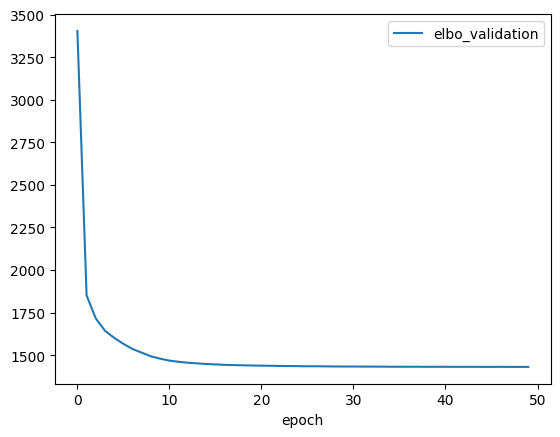

In [ ]:
# we start the first step of the EBMoCAVI model training
# this consists in standard MoCAVI training to learn disentangled latent representations
train = True
max_epochs = 100
vehicle_indices = np.where(adata.obs["perturb_DE"] == "Control")[0]
target_indices = np.where(adata.obs["perturb_DE"] != "Control")[0]
adata.uns["protein_names"] = list(adata.obsm["raw_proteins"].columns)
if train:
    EBMoCAVIModel.setup_anndata(
        adata,
        batch_key="batch",
        labels_key="perturb_DE",
        layer="counts",
        protein_expression_obsm_key="raw_proteins",
        protein_names_uns_key="protein_names",
        empirical_prior_key="embedding_ops",
    )

    # train the VAE
    model = EBMoCAVIModel(
        adata,
        n_genes=adata.n_vars,
        n_regions=0,
        n_salient_latent=50,
        n_background_latent=8,
        n_layers_decoder=2,
        reweighting_mode="auto",
        wasserstein_reg=0.01,
        n_layers_encoder=2,
    )
    model.train(
        max_epochs=max_epochs,
        background_indices=vehicle_indices,
        target_indices=target_indices,
        check_val_every_n_epoch=1,
        early_stopping=True,
        plan_kwargs={
            "n_epochs_kl_warmup": int(max_epochs * 0.8),
            "lr": 0.001,
        },
    )
    model.history["elbo_train"].plot()
    model.history["elbo_validation"].plot()
    model.save("data/ebmocavi_embedding_ops_model", overwrite=True)
else:
    model = EBMoCAVIModel.load("data/ebmocavi_embedding_ops_model", adata)
    model.history["elbo_train"].plot()
    model.history["elbo_validation"].plot()

In [18]:
# our second training step consists in fitting the empirical prior with maximum likelihood
# this allows us to map the OPS embeddings to the latent space learned by MoCAVI
# later, we will be able to generate perturbation effects by sampling from the empirical prior for unseen perturbations

# note: this function the presence of a reference label in the data, here "Control".
# The labels used are the same as those used in the initial MoCAVI training (here "perturb_DE")
finetune = True
finetune_max_epochs = 5
finetune_n_samples_per_cell = 10
if finetune:
    model.maximum_likelihood_training(
        learning_rate=1e-3,
        n_samples_per_cell=finetune_n_samples_per_cell,
        max_epochs=finetune_max_epochs,
        control_label="Control",
    )
    model.save("data/ebmocavi_predictor_fine_tuned_embedding_ops_model", overwrite=True)
else:
    model = EBMoCAVIModel.load("data/ebmocavi_predictor_fine_tuned_embedding_ops_model", adata)

100%|██████████| 858/858 [00:09<00:00, 93.27it/s]


Epoch 1/5, Avg NLL: 79.819267


100%|██████████| 858/858 [00:09<00:00, 94.51it/s]


Epoch 2/5, Avg NLL: 79.467598


100%|██████████| 858/858 [00:09<00:00, 94.70it/s]


Epoch 3/5, Avg NLL: 79.383167


100%|██████████| 858/858 [00:09<00:00, 93.99it/s]


Epoch 4/5, Avg NLL: 79.346681


100%|██████████| 858/858 [00:09<00:00, 93.84it/s]


Epoch 5/5, Avg NLL: 79.320636


In [19]:
# now we would like to create a dataframe with the embedding of each perturbations we would like to predict or denoise
dict_emb_ops = {}
for perturbation in tqdm(bulk_ops.obs_names):
    # get the perturbation of the cell
    dict_emb_ops[perturbation] = np.array(bulk_ops[perturbation].X)[0]

100%|██████████| 514/514 [00:00<00:00, 2077.58it/s]


In [20]:
# A first downstream task for EBMoCAVI is to predict the effect of unseen perturbations
# To do so, we can use the learned empirical prior to sample from the latent space.
# As EBMoCAVI is a generative model, we can then obtain different kinds of predictions:
# 1. the predicted fold change in expression compared to control
# 2. the predicted normalized expression values
# 3. the salient latent embedding
# 4. the background latent embedding
# We show here how to obtain these different predictions
prediction_dict = model.get_label_prior_total_fold_change(labels=dict_emb_ops, n_samples=100, control_label="Control")
de_exp = prediction_dict["fold_change_exp"]
normalized_values = prediction_dict["normalized_exp"]
salient_embedding = prediction_dict["salient"]
background_embedding = prediction_dict["background"]

260it [00:02, 110.71it/s]
514it [00:03, 133.59it/s]


In [ ]:
# A second downstream task for EBMoCAVI is to denoise training data in the case of perturbations with low cell numbers
# We specifically advise to use this function only when:
# 1. the number of cells per perturbation is low (<50) [if > 100 cells, this function will not have an effect]
# 2. the perturbation is not detected as having a significant effect compared to control
# The processed data below has only significant perturbations, so we just show how to use the function

# Note: for > 100 cells per perturbation, the code below will return the differential expressio
# for 0 cell per perturbation, it will return the same values as the prediction function above

# Step 1: import the anndata with the perturbation that have low cell numbers
adata_denoise = adata.copy()
# Step 2: make a dictionary with the embeddings of the perturbations to denoise
dict_denoise_emb_ops = {}
for perturbation in adata_denoise.obs["perturb_DE"].unique().tolist():
    if perturbation == "Control":
        dict_denoise_emb_ops[perturbation] = np.zeros((bulk_ops.shape[1],))
    else:
        dict_denoise_emb_ops[perturbation] = np.array(bulk_ops[perturbation].X)[0]
# Step 3: get the denoised outputs
denoise_dict = model.get_label_shrinkage_total_fold_change(
    dict_denoise_emb_ops, adata=adata_denoise, batch_size=1000, n_samples=100, control_label="Control"
)

# same as before, we can obtain different kinds of denoised outputs:
# 1. the denoised fold change in expression compared to control
# 2. the denoised normalized expression values
# 3. the denoised salient latent embedding
# 4. the denoised background latent embedding
denoised_de_exp = denoise_dict["fold_change_exp"]
denoised_normalized_values = denoise_dict["normalized_exp"]
denoised_salient_embedding = denoise_dict["salient"]
denoised_background_embedding = denoise_dict["background"]

Processing labels: 100%|██████████| 515/515 [00:17<00:00, 29.87it/s]
